# 02: Decarbonisation Scenarios, MACC & Net-Zero Pathway

**Question for the board:** *Which reduction levers should EcoNaija Manufacturing Ltd fund, in what order, and do they put the company on an SBTi-aligned path?*

Method (see `src/carbon/scenarios.py`):
1. Baseline = 2025 annual activity by site.
2. Nine levers (`data/reference/reduction_levers.csv`) are applied **in order** to the residual activity, so they are never double-counted.
3. Annualised cost = capex × CRF(12%, lifetime) + opex − fuel/energy savings. Cost per tCO2e = annualised cost ÷ abatement.
4. Pathway to 2035 with +2%/yr business growth, compared with SBTi minimum rates (Scope 1+2: 4.2%/yr, Scope 3: 2.5%/yr, from 2023).

> Activity data and company profile are **synthetic**. Fuel prices, tariff and FX are **sourced 2026 Nigerian market values**. Lever capex and opex are **documented assumptions**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))
import pandas as pd
from IPython.display import Image, display
from carbon import load_activity, load_factors, calculate_emissions
from carbon.scenarios import (load_levers, load_cost_assumptions, load_profile, baseline_activity,
                              apply_levers, pathway, intensity_metrics, scope2_dual)
pd.set_option('display.float_format', '{:,.1f}'.format)

activity, factors = load_activity(), load_factors()
emissions = calculate_emissions(activity, factors)
A = load_cost_assumptions()
pd.read_csv('../data/reference/cost_assumptions.csv')[['parameter', 'value', 'unit', 'source']]

,parameter,value,unit,source
0,fx_ngn_per_usd,"1,350.0",NGN per USD,Assumption based on NAFEM / market rates Sep 2...
1,diesel_price_ngn_per_litre,"1,900.0",NGN per litre,Lagos depot N1850-1900/L (19-23 Oct 2026); Dan...
2,petrol_price_ngn_per_litre,"1,400.0",NGN per litre,Median depot PMS ~N1353/L (15 Sep 2026); NBS p...
3,grid_tariff_ngn_per_kwh,209.5,NGN per kWh,NERC Band A tariff N209.50/kWh (MYTO supplemen...
4,flight_domestic_usd_per_pkm,0.2,USD per passenger-km,Assumption: ~USD110 one-way Lagos-Abuja (~520 km)
5,flight_longhaul_usd_per_pkm,0.1,USD per passenger-km,Assumption: ~USD900 economy return Lagos-Londo...
6,refrigerant_usd_per_kg,25.0,USD per kg,Assumption: R-410A recharge cost
7,landfill_gate_fee_usd_per_tonne,25.0,USD per tonne,Assumption: private waste collection and dispo...
8,discount_rate,0.1,fraction,Assumption: real USD cost of capital for Niger...
9,bau_growth_rate,0.0,fraction per year,Assumption: business-as-usual activity growth ...


## 1. Lever results

In [2]:
results, residual = apply_levers(baseline_activity(activity, 2025), load_levers(), factors, A, 2025)
results[['lever_id', 'lever', 'scope', 'accounting', 'abatement_tco2e', 'capex_usd',
         'annual_savings_usd', 'cost_per_tco2e_usd', 'simple_payback_years']].sort_values('cost_per_tco2e_usd')

,lever_id,lever,scope,accounting,abatement_tco2e,capex_usd,annual_savings_usd,cost_per_tco2e_usd,simple_payback_years
4,L5,Travel policy (virtual-first + economy-only),3,location,67.0,"15,000.0","58,574.5",-811.8,0.3
1,L2,Solar-battery hybrid at Port Harcourt Plant,1,location,215.2,"216,000.0","113,786.0",-361.4,2.0
0,L1,Energy efficiency (LED + inverter ACs + motor ...,2,location,120.1,"70,000.0","40,885.0",-220.5,1.8
2,L3,Rooftop solar PV (grid-tied) at Lagos HQ & Abu...,2,location,96.3,"111,000.0","32,757.5",-150.6,3.8
5,L6,Hybrid working policy (2 remote days per week),3,location,83.0,0.0,0.0,0.0,NaN
8,L9,Renewable PPA / I-RECs for Port Harcourt Plant...,2,market,248.0,0.0,0.0,44.0,NaN
3,L4,Refrigerant leak detection & maintenance progr...,1,location,61.9,"8,000.0",804.4,61.5,NaN
6,L7,Waste segregation & recycling programme,3,location,35.6,"4,000.0","1,788.8",121.4,NaN
7,L8,Supplier engagement programme (top 20 suppliers),3,location,120.5,0.0,0.0,249.0,NaN


In [3]:
base_2025 = emissions.loc[emissions.year == 2025, 'tco2e'].sum()
phys = results[results.accounting == 'location']
print(f"Physical abatement:       {phys.abatement_tco2e.sum():,.0f} tCO2e/yr ({phys.abatement_tco2e.sum()/base_2025:.0%} of 2025)")
print(f"+ PPA (market-based):     {results.abatement_tco2e.sum():,.0f} tCO2e/yr ({results.abatement_tco2e.sum()/base_2025:.0%})")
print(f"Total capex:              ${results.capex_usd.sum():,.0f}")
print(f"Net annualised saving:    ${-results.annualised_cost_usd.sum():,.0f}/yr")
neg = results[results.cost_per_tco2e_usd < 0]
print(f"Cost-negative levers:     {len(neg)} of {len(results)}, delivering {neg.abatement_tco2e.sum()/results.abatement_tco2e.sum():.0%} of abatement")

Physical abatement:       800 tCO2e/yr (21% of 2025)
+ PPA (market-based):     1,048 tCO2e/yr (27%)
Total capex:              $424,000
Net annualised saving:    $124,152/yr
Cost-negative levers:     4 of 9, delivering 48% of abatement


## 2. Marginal abatement cost curve

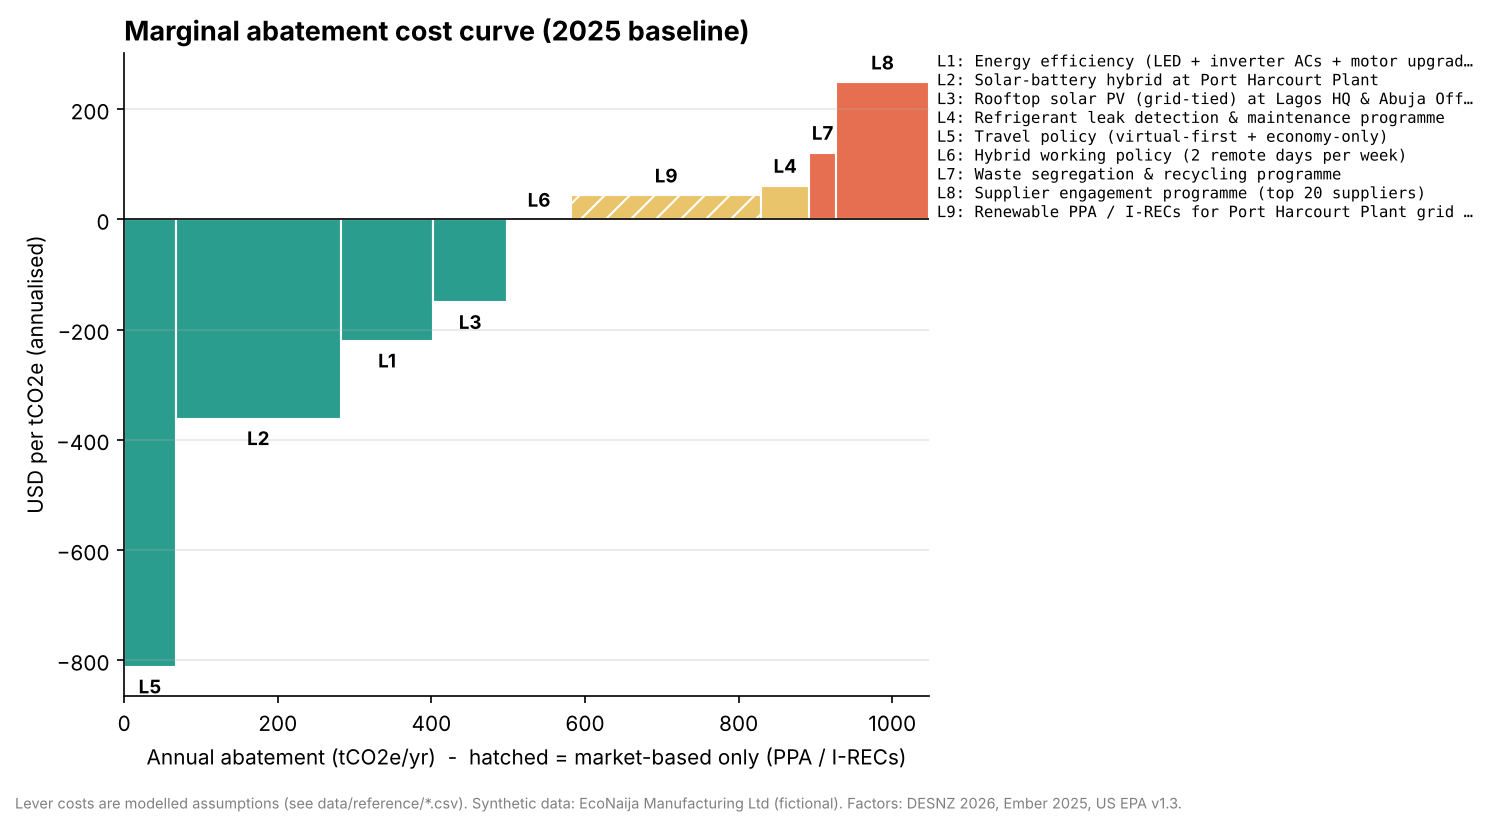

In [4]:
display(Image('../reports/figures/05_macc_curve.png'))

## 3. Pathway vs SBTi-aligned target

In [5]:
path = pathway(emissions, results, base_year=2023, baseline_year=2025, end_year=2035, growth=A['bau_growth_rate'])
path[path.year.isin([2023, 2025, 2027, 2030, 2035])][
    ['year', 'actual', 'bau', 'with_levers_location', 'with_levers_market', 'sbti_target',
     'with_levers_market_s12', 'sbti_target_s12', 'with_levers_market_s3', 'sbti_target_s3']].set_index('year').T

year,2023,2025,2027,2030,2035
actual,"4,292.1","3,881.0",NaN,NaN,NaN
bau,NaN,"3,881.0","4,037.8","4,284.9","4,730.9"
with_levers_location,NaN,"3,881.0","3,205.8","3,402.1","3,756.2"
with_levers_market,NaN,"3,881.0","2,947.8","3,128.3","3,453.8"
sbti_target,"4,292.1","3,998.4","3,704.7","3,264.1","2,529.9"
with_levers_market_s12,NaN,"2,144.3","1,459.5","1,548.8","1,710.0"
sbti_target_s12,"2,326.2","2,130.8","1,935.4","1,642.3","1,153.8"
with_levers_market_s3,NaN,"1,736.7","1,488.4","1,579.4","1,743.8"
sbti_target_s3,"1,965.9","1,867.6","1,769.3","1,621.9","1,376.1"


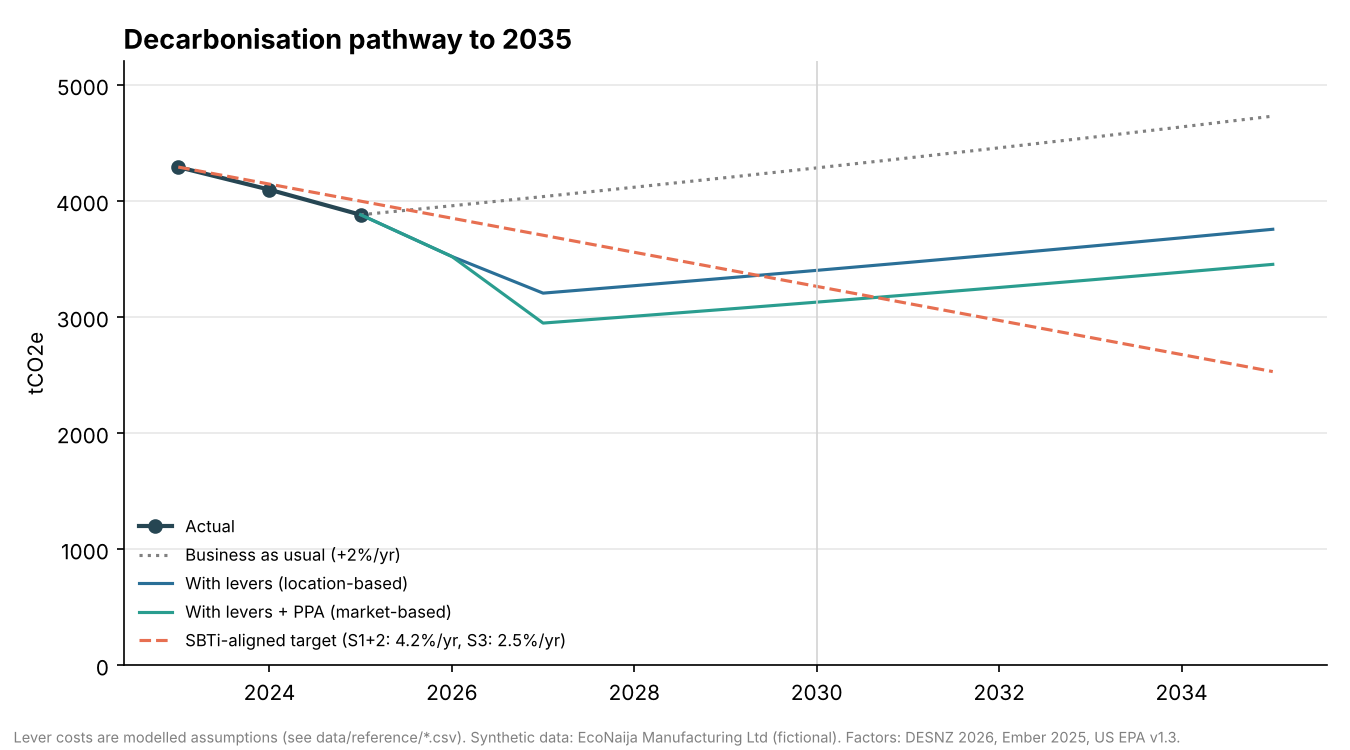

In [6]:
display(Image('../reports/figures/06_decarbonisation_pathway.png'))

## 4. Sensitivity: what if diesel gets cheaper?

In [7]:
rows = []
for price in (1200, 1600, 1900, 2400, 3200):
    a = {**A, 'diesel_price_ngn_per_litre': price}
    r, _ = apply_levers(baseline_activity(activity, 2025), load_levers(), factors, a, 2025)
    solar = r[r.lever_id == 'L2'].iloc[0]
    rows.append({'diesel_ngn_per_l': price, 'L2_cost_per_tco2e': solar.cost_per_tco2e_usd,
                 'L2_payback_years': solar.simple_payback_years, 'portfolio_net_saving_usd': -r.annualised_cost_usd.sum()})
pd.DataFrame(rows)

,diesel_ngn_per_l,L2_cost_per_tco2e,L2_payback_years,portfolio_net_saving_usd
0,1200,-166.6,3.2,"82,230.4"
1,1600,-277.9,2.4,"106,185.3"
2,1900,-361.4,2.0,"124,151.6"
3,2400,-500.6,1.5,"154,095.2"
4,3200,-723.2,1.2,"202,005.2"


## 5. Intensity metrics & dual Scope 2 reporting

In [8]:
intensity_metrics(emissions, load_profile())[['year', 'tco2e', 'tco2e_per_employee', 'tco2e_per_usd_m_revenue', 'kgco2e_per_tonne_product']]

,year,tco2e,tco2e_per_employee,tco2e_per_usd_m_revenue,kgco2e_per_tonne_product
0,2023,"4,292.1",10.2,112.9,82.5
1,2024,"4,097.2",9.4,99.9,75.9
2,2025,"3,881.0",8.6,88.2,70.6


In [9]:
ppa_kwh_2027 = results.loc[results.lever_id == 'L9', 'abatement_tco2e'].iloc[0] * 1000 / 0.456
print(f"PPA covers ~{ppa_kwh_2027:,.0f} kWh/yr once contracted")
scope2_dual(emissions, {2025: ppa_kwh_2027})  # illustrative: as if the PPA had been in place in 2025

PPA covers ~543,846 kWh/yr once contracted


,year,kwh,location_tco2e,contractual_kwh,market_tco2e
0,2023,"2,376,020.8","1,083.5",0.0,"1,083.5"
1,2024,"2,260,844.9","1,030.9",0.0,"1,030.9"
2,2025,"2,195,497.5","1,001.1","543,846.3",753.2


## 6. Recommendations

1. **Fund the cost-negative levers first (L5, L2, L1, L3).** Travel policy, the Port Harcourt solar-battery hybrid, efficiency and rooftop solar all *save money*. The solar hybrid pays back in ~2 years at 2026 diesel prices and stays attractive even if diesel falls to ₦1,200/L.
2. **The solar hybrid at Port Harcourt is the flagship project.** It is the single biggest physical lever (~215 tCO2e/yr) and also protects the plant against diesel price shocks.
3. **Physical levers alone cut ~21% vs 2025, which is not enough for 2030 on a location basis.** Meeting both SBTi lines in 2030 requires the **renewable PPA (L9)**, which is market-based only.
4. **Growth erodes the gains after 2027.** With +2%/yr growth, emissions rise again and miss the 2035 target. A second wave is needed by ~2029: a larger supplier programme (Cat 1 is still ~30% of the footprint), fleet conversion (CNG/EV) and expanded on-site solar.
5. **Fix the data first.** Cat 1 relies on a generic spend proxy. Supplier-specific data could move the baseline by ±50%, so it is the highest-value data-strategy investment.
